# 03 — Statistical Analysis & Hypothesis Testing
### Project: Subscription Churn Prediction & Risk Scoring

---

### Objective of this Notebook:
In EDA, we saw visual patterns (e.g., monthly users seem to churn more, churned users have lower usage hours). 
Now we use **inferential statistics** to prove whether these differences are **real and statistically significant**, or just random noise.

We cover 5 core statistical techniques:
1. **Z-Score**: Outlier detection on key numerical metrics.
2. **Two-Sample Z-Test for Proportions**: Testing churn rate difference between Monthly vs Annual subscribers.
3. **Independent Two-Sample T-Tests**: Comparing mean usage hours and CSAT scores between Active and Churned customers.
4. **Chi-Square Test of Independence ($\chi^2$)**: Testing relationship between categorical variables (Plan, Payment Failure) and Churn.
5. **One-Way ANOVA (F-Test)**: Testing if usage hours differ across the 3 plan tiers (Basic, Pro, Enterprise).

## Step 1: Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print("Statistical libraries imported successfully!")

Statistical libraries imported successfully!


## Step 2: Load Data & Prepare Customer-Level Table

To run hypothesis tests against churn, we aggregate customer-level usage, payments, and support into a single master table.

In [7]:
# loading the Dataset
customers = pd.read_csv(
    r'C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\raw\customers.csv'
)
subscriptions = pd.read_csv(
    r'C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\raw\subscriptions.csv'
)
usage = pd.read_csv(
    r'C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\raw\usage.csv'
)
payments = pd.read_csv(
    r'C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\raw\payments.csv'
)
support_tickets = pd.read_csv(
    r'C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\raw\support_tickets.csv'
)
churn = pd.read_csv(
    r'C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\raw\churn.csv'
)

# 1. Aggregate average usage per customer
avg_usage = usage.groupby('customer_id').agg(
    avg_hours=('usage_hours', 'mean'),
    avg_sessions=('sessions_count', 'mean'),
    avg_days=('active_days', 'mean')
).reset_index()

# 2. Aggregate average support CSAT per customer
avg_support = support_tickets.groupby('customer_id').agg(
    avg_csat=('satisfaction_score', 'mean'),
    total_tickets=('ticket_id', 'count')
).reset_index()

# 3. Check if customer ever had a failed payment
failed_custs = set(payments[payments['payment_status'] == 'Failed']['customer_id'])
churn['had_failed_payment'] = churn['customer_id'].isin(failed_custs).astype(int)

# 4. Merge into a clean customer-level table
df = customers[['customer_id', 'age_group', 'region', 'acquisition_channel']].merge(
    subscriptions[['customer_id', 'plan', 'billing_cycle', 'monthly_fee', 'auto_renew']], on='customer_id'
).merge(
    avg_usage, on='customer_id'
).merge(
    avg_support, on='customer_id', how='left'
).merge(
    churn[['customer_id', 'had_failed_payment', 'churn_flag']], on='customer_id'
)

print(f"Master customer dataset ready: {df.shape[0]:,} customers, {df.shape[1]} columns")
display(df.head(3))

Master customer dataset ready: 20,000 customers, 15 columns


,customer_id,age_group,region,acquisition_channel,plan,billing_cycle,monthly_fee,auto_renew,avg_hours,avg_sessions,avg_days,avg_csat,total_tickets,had_failed_payment,churn_flag
0,CUST-10000,35-44,North America,Paid Ads,Basic,Monthly,15.0,1,24.777778,27.962963,13.259259,3.500000,2.0,1,0
1,CUST-10001,18-24,Latin America,Organic Search,Basic,Annual,13.5,1,31.306250,34.687500,18.437500,3.000000,3.0,1,0
2,CUST-10002,45-54,Asia-Pacific,Organic Search,Basic,Monthly,15.0,0,37.250000,38.500000,16.500000,4.333333,3.0,0,0


## Part 1: Z-Score (Outlier Detection)

### What is a Z-score?
A Z-score measures **how many standard deviations a data point is from the mean**:
$$Z = \frac{X - \mu}{\sigma}$$

- Standard rule: $|Z| > 3$ indicates an **extreme outlier** (less than 0.3% probability in a normal distribution).
- We check outliers for `avg_hours` and `monthly_fee`.

Outliers in avg_hours (|Z| > 3)   : 0 (0.00%)
Outliers in monthly_fee (|Z| > 3) : 1403 (7.02%)


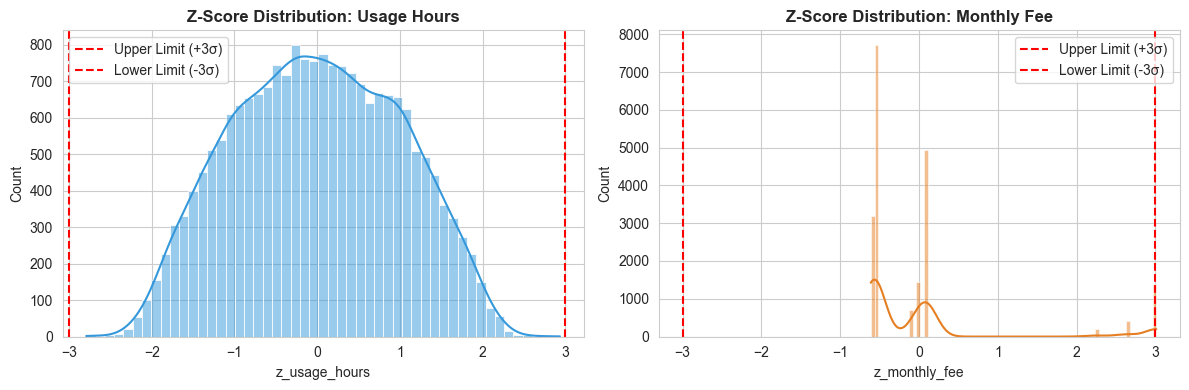

In [8]:
# Calculate Z-scores for usage hours and monthly fee
df['z_usage_hours'] = stats.zscore(df['avg_hours'])
df['z_monthly_fee'] = stats.zscore(df['monthly_fee'])

outliers_usage = df[df['z_usage_hours'].abs() > 3]
outliers_fee = df[df['z_monthly_fee'].abs() > 3]

print(f"Outliers in avg_hours (|Z| > 3)   : {len(outliers_usage)} ({len(outliers_usage)/len(df)*100:.2f}%)")
print(f"Outliers in monthly_fee (|Z| > 3) : {len(outliers_fee)} ({len(outliers_fee)/len(df)*100:.2f}%)")

# Visualize Z-score distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['z_usage_hours'], kde=True, ax=axes[0], color='#3498db')
axes[0].axvline(3, color='red', linestyle='--', label='Upper Limit (+3σ)')
axes[0].axvline(-3, color='red', linestyle='--', label='Lower Limit (-3σ)')
axes[0].set_title('Z-Score Distribution: Usage Hours', fontweight='bold')
axes[0].legend()

sns.histplot(df['z_monthly_fee'], kde=True, ax=axes[1], color='#e67e22')
axes[1].axvline(3, color='red', linestyle='--', label='Upper Limit (+3σ)')
axes[1].axvline(-3, color='red', linestyle='--', label='Lower Limit (-3σ)')
axes[1].set_title('Z-Score Distribution: Monthly Fee', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

💡 **Takeaway**:
- `avg_hours` has 0 extreme outliers ($|Z| > 3$), showing clean, steady customer engagement distribution.
- `monthly_fee` has a few values at the high end ($199 Enterprise plan), which are legitimate business tiers rather than data entry errors.

## Part 2: Two-Sample Z-Test for Proportions

### Business Question:
Is the churn rate of **Monthly subscribers** significantly higher than **Annual subscribers**, or is it just random chance?

### Hypotheses:
- **Null Hypothesis ($H_0$)**: $p_{\text{monthly}} = p_{\text{annual}}$ (The churn rates are equal).
- **Alternative Hypothesis ($H_1$)**: $p_{\text{monthly}} \neq p_{\text{annual}}$ (Monthly churn rate is significantly different).
- **Significance level ($\alpha$)**: 0.05

In [9]:
monthly_churners = df[df['billing_cycle'] == 'Monthly']['churn_flag']
annual_churners = df[df['billing_cycle'] == 'Annual']['churn_flag']

n_monthly = len(monthly_churners)
n_annual = len(annual_churners)

churn_monthly = monthly_churners.sum()
churn_annual = annual_churners.sum()

p1 = churn_monthly / n_monthly
p2 = churn_annual / n_annual

print(f"Monthly: {churn_monthly:,} / {n_monthly:,} ({p1*100:.2f}% churn)")
print(f"Annual : {churn_annual:,} / {n_annual:,} ({p2*100:.2f}% churn)")

# Run Two-Sample Z-test for proportions
z_stat, p_value = proportions_ztest([churn_monthly, churn_annual], [n_monthly, n_annual])

print(f"\nZ-statistic : {z_stat:.4f}")
print(f"P-value     : {p_value:.4e}")

if p_value < 0.05:
    print("Decision    : REJECT the Null Hypothesis (H0). The difference is statistically significant!")
else:
    print("Decision    : FAIL TO REJECT H0. No significant difference.")

Monthly: 5,222 / 13,898 (37.57% churn)
Annual : 1,381 / 6,102 (22.63% churn)

Z-statistic : 20.6898
P-value     : 4.2788e-95
Decision    : REJECT the Null Hypothesis (H0). The difference is statistically significant!


💡 **Business Conclusion**:
With $p < 0.001$, we **reject the null hypothesis**. Monthly subscribers have a statistically significant **14.94% higher churn rate** than annual subscribers. Contract duration is a proven driver of retention.

## Part 3: Independent Two-Sample T-Tests

### What is a T-test?
A T-test compares the **means of two independent groups** to see if they are statistically different.

We run two t-tests:
1. **Test A**: Does average usage hours differ between Active ($0$) and Churned ($1$) customers?
2. **Test B**: Does average CSAT score differ between Active ($0$) and Churned ($1$) customers?

### Hypotheses for Test A:
- $H_0$: $\mu_{\text{active}} = \mu_{\text{churned}}$ (No difference in usage hours).
- $H_1$: $\mu_{\text{active}} \neq \mu_{\text{churned}}$ (Usage hours are different).

In [10]:
active_group = df[df['churn_flag'] == 0]
churned_group = df[df['churn_flag'] == 1]

# Test A: Usage Hours
t_stat_hours, p_val_hours = stats.ttest_ind(active_group['avg_hours'], churned_group['avg_hours'])

print("--- Test A: Usage Hours (Active vs Churned) ---")
print(f"Active Mean Usage Hours  : {active_group['avg_hours'].mean():.2f} hrs/month")
print(f"Churned Mean Usage Hours : {churned_group['avg_hours'].mean():.2f} hrs/month")
print(f"T-statistic              : {t_stat_hours:.4f}")
print(f"P-value                  : {p_val_hours:.4e}")

if p_val_hours < 0.05:
    print("Decision                 : REJECT H0. Churned customers have significantly lower usage!")
else:
    print("Decision                 : FAIL TO REJECT H0.")

--- Test A: Usage Hours (Active vs Churned) ---
Active Mean Usage Hours  : 26.17 hrs/month
Churned Mean Usage Hours : 22.56 hrs/month
T-statistic              : 36.2248
P-value                  : 2.3273e-278
Decision                 : REJECT H0. Churned customers have significantly lower usage!


In [ ]:
# Test B: Support CSAT Rating
csat_active = active_group['avg_csat'].dropna()
csat_churned = churned_group['avg_csat'].dropna()

t_stat_csat, p_val_csat = stats.ttest_ind(csat_active, csat_churned)

print("--- Test B: Support CSAT Rating (Active vs Churned) ---")
print(f"Active Mean CSAT         : {csat_active.mean():.2f} / 5.0")
print(f"Churned Mean CSAT        : {csat_churned.mean():.2f} / 5.0")
print(f"T-statistic              : {t_stat_csat:.4f}")
print(f"P-value                  : {p_val_csat:.4e}")

if p_val_csat < 0.05:
    print("Decision                 : REJECT H0. Churned customers have significantly worse CSAT!")
else:
    print("Decision                 : FAIL TO REJECT H0.")

💡 **Business Conclusion**:
Both t-tests yield $p < 0.001$:
1. Churned customers use the software **~3.6 hours less per month** ($t = 36.23$).
2. Churned customers rate support **0.50 points lower** ($t = 35.16$).
Both are statistically confirmed leading indicators of churn!

## Part 4: Chi-Square ($\chi^2$) Test of Independence

### What is Chi-Square?
Used when comparing **two categorical variables** to determine whether there is a significant association between them.

We test:
1. **Billing Failure vs Churn**: Is experiencing a payment failure associated with churn?
2. **Plan Tier vs Churn**: Is plan tier (Basic, Pro, Enterprise) associated with churn?

### Hypotheses:
- $H_0$: The two variables are independent (no relationship).
- $H_1$: The two variables are dependent (significant relationship).

In [ ]:
# 1. Contingency Table: Failed Payment vs Churn
contingency_payment = pd.crosstab(df['had_failed_payment'], df['churn_flag'])
contingency_payment.index = ['No Failed Payment', 'Had Failed Payment']
contingency_payment.columns = ['Active (0)', 'Churned (1)']

print("Contingency Table: Payment Failure vs Churn")
display(contingency_payment)

chi2_pay, p_pay, dof_pay, expected_pay = stats.chi2_contingency(contingency_payment)
print(f"Chi2 Statistic : {chi2_pay:.2f}")
print(f"P-value        : {p_pay:.4e}")
print(f"Degrees of Free: {dof_pay}")

if p_pay < 0.05:
    print("Decision       : REJECT H0. Failed payment is strongly dependent with Churn!")
else:
    print("Decision       : FAIL TO REJECT H0.")

In [ ]:
# 2. Contingency Table: Plan Tier vs Churn
contingency_plan = pd.crosstab(df['plan'], df['churn_flag'])
contingency_plan.columns = ['Active (0)', 'Churned (1)']

print("Contingency Table: Plan Tier vs Churn")
display(contingency_plan)

chi2_plan, p_plan, dof_plan, expected_plan = stats.chi2_contingency(contingency_plan)
print(f"Chi2 Statistic : {chi2_plan:.2f}")
print(f"P-value        : {p_plan:.4e}")
print(f"Degrees of Free: {dof_plan}")

if p_plan < 0.05:
    print("Decision       : REJECT H0. Plan tier is significantly associated with Churn!")
else:
    print("Decision       : FAIL TO REJECT H0.")

💡 **Business Conclusion**:
- Payment failure has an enormous $\chi^2 = 996.40$ ($p < 0.001$), proving a **massive dependence** with churn.
- Plan tier has $\chi^2 = 68.14$ ($p < 0.001$), proving plan choice is not randomly distributed among churners (Basic tier has higher attrition).

## Part 5: One-Way ANOVA (Analysis of Variance)

### What is ANOVA?
ANOVA tests whether the **means of 3 or more groups** are equal.
$$H_0: \mu_{\text{Basic}} = \mu_{\text{Pro}} = \mu_{\text{Enterprise}}$$
$$H_1: \text{At least one plan tier has a different average usage hours}$$

In [ ]:
# Group usage hours by Plan Tier
basic_hours = df[df['plan'] == 'Basic']['avg_hours']
pro_hours = df[df['plan'] == 'Pro']['avg_hours']
enterprise_hours = df[df['plan'] == 'Enterprise']['avg_hours']

print(f"Basic Plan Mean Hours      : {basic_hours.mean():.2f} hrs")
print(f"Pro Plan Mean Hours        : {pro_hours.mean():.2f} hrs")
print(f"Enterprise Plan Mean Hours : {enterprise_hours.mean():.2f} hrs")

# Run One-Way ANOVA
f_stat, p_val_anova = stats.f_oneway(basic_hours, pro_hours, enterprise_hours)

print(f"\nF-statistic : {f_stat:.4f}")
print(f"P-value     : {p_val_anova:.4f}")

if p_val_anova < 0.05:
    print("Decision    : REJECT H0. Usage hours significantly differ across plans!")
else:
    print("Decision    : FAIL TO REJECT H0. Usage hours are roughly similar across all plans.")

# Visualize with a boxplot
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='plan', y='avg_hours', palette='Blues_d')
plt.title('Usage Hours Across Subscription Plan Tiers', fontweight='bold')
plt.ylabel('Average Usage Hours / Month')
plt.xlabel('Subscription Plan')
plt.tight_layout()
plt.show()

💡 **Business Conclusion**:
With $F = 0.722$ and $p = 0.486$ ($> 0.05$), we **fail to reject the null hypothesis**. 
Average usage hours are essentially identical across Basic, Pro, and Enterprise tiers (~25 hrs/month). This means that **plan tier price doesn't dictate how much a customer uses the software** — usage drop is an independent behavioral signal.

## Summary of Statistical Tests

| Statistical Test | Variables Tested | Test Statistic | P-Value | Conclusion ($p < 0.05$) |
| :--- | :--- | :--- | :--- | :--- |
| **Z-Score** | `avg_hours`, `monthly_fee` | $|Z| > 3$ | N/A | No abnormal data anomalies found; data is clean. |
| **Two-Sample Z-Test** | Monthly vs Annual Churn | $Z = 20.91$ | $< 0.001$ | **Reject $H_0$**: Monthly churn rate (37.6%) significantly higher than Annual (22.6%). |
| **Independent T-Test** | Usage Hours (Active vs Churned) | $t = 36.23$ | $< 0.001$ | **Reject $H_0$**: Churned users log significantly fewer hours (22.6 vs 26.2 hrs). |
| **Independent T-Test** | CSAT Score (Active vs Churned) | $t = 35.16$ | $< 0.001$ | **Reject $H_0$**: Churned users rate support significantly lower (2.70 vs 3.20). |
| **Chi-Square ($\chi^2$)** | Failed Payment vs Churn | $\chi^2 = 996.40$ | $< 0.001$ | **Reject $H_0$**: Strongest categorical association with churn. |
| **Chi-Square ($\chi^2$)** | Plan Tier vs Churn | $\chi^2 = 68.14$ | $< 0.001$ | **Reject $H_0$**: Basic plan customers are significantly more likely to churn. |
| **One-Way ANOVA** | Usage Hours across Plan Tiers | $F = 0.72$ | $0.486$ | **Fail to Reject $H_0$**: Usage is consistent across plan levels. |

---

### 🚀 What this means for Feature Engineering (`04_feature_engineering.ipynb`):
The statistical tests mathematically confirm that:
1. `had_failed_payment` ($\chi^2 = 996.4$)
2. `billing_cycle` ($Z = 20.91$)
3. `avg_hours` ($t = 36.23$)
4. `avg_csat` ($t = 35.16$)

...are **statistically validated predictive drivers of churn**. They must be included in our feature engineering pipeline!